# Phase 2 — Clustering occupations by task text (NLP)

**Pipeline:** task statements → sentence embeddings (`all-mpnet-base-v2`) → UMAP → HDBSCAN vs. K-Means

Embeddings are built by `src/embed.py`: each task statement (and the title + description) is embedded
separately, then averaged into one 768-dim vector per occupation. This avoids the model truncating long task lists.

In [1]:
import sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, "../src")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from text_clustering import *
from load_onet import PROCESSED
pd.set_option("display.max_colwidth", 140)

X, codes = load_embeddings("all-mpnet-base-v2")
occ = pd.read_csv(PROCESSED / "occupations.csv").set_index("code")
interests = pd.read_csv(PROCESSED / "interests.csv").set_index("code")
titles = occ.loc[codes, "title"].reset_index(drop=True)

# Existing groupings to compare against (Adjusted Rand Index)
reference = {
    "SOC": codes.str[:2],                                                   # O*NET's own job families
    "RIASEC": interests.loc[codes, "top_interest"].reset_index(drop=True),  # top career interest
}
X.shape

(923, 768)

## 1. Dimension reduction (UMAP)
768 dimensions makes distances less meaningful (the curse of dimensionality). UMAP with cosine distance
keeps local neighborhoods intact. We use **10 dims for clustering** and **2 dims for plotting only**.

In [2]:
X10 = reduce(X, n_components=10)
X2 = reduce(X, n_components=2)
np.save(PROCESSED / "umap10.npy", X10)
np.save(PROCESSED / "umap2.npy", X2)

### 1b. Does dimension reduction help? Raw vs. PCA vs. UMAP

The README suggests UMAP **or** PCA. Here we compare four spaces, each clustered with the same settings
(K-Means K=30; HDBSCAN `min_cluster_size=10, min_samples=3`):

| Space | What it is |
|---|---|
| raw 768d | the embeddings as they are |
| PCA 10d / 50d | linear projection onto the top 10 / 50 principal components (10 keep ~50% of the variance, 50 keep ~83%) |
| UMAP 10d | non-linear projection that preserves each job's nearest neighbors |

**Fair scoring.** Silhouette measured inside each reduced space isn't comparable (UMAP packs clusters tightly by design,
which inflates its own silhouette). So every result is scored **in the original 768d space with cosine distance**.

Also measured:
- **Trustworthiness** (0–1): how well each job's 15 nearest neighbors survive the reduction.
- **Relative contrast**: `(farthest − nearest) / nearest` distance, averaged over jobs. Close to 1 means all points look
  equally far apart, which is the "curse of dimensionality" the README mentions; density methods need high contrast.

In [3]:
from sklearn.decomposition import PCA
from sklearn.manifold import trustworthiness
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.metrics import pairwise_distances
from sklearn.metrics.pairwise import cosine_distances

pca_full = PCA(random_state=SEED).fit(X)
cum = pca_full.explained_variance_ratio_.cumsum()
print(f"PCA: 10 components keep {cum[9]:.0%} of variance, 50 keep {cum[49]:.0%}")

spaces = {
    "raw 768d": X,
    "PCA 10d": PCA(10, random_state=SEED).fit_transform(X),
    "PCA 50d": PCA(50, random_state=SEED).fit_transform(X),
    "UMAP 10d": X10,
}
D = cosine_distances(X)  # original-space distances used to score every result

def relative_contrast(R):
    d = pairwise_distances(R); np.fill_diagonal(d, np.nan)
    return np.nanmean((np.nanmax(d, 1) - np.nanmin(d, 1)) / np.nanmin(d, 1))

rows = []
for name, R in spaces.items():
    km = run_kmeans(R, 30).labels_
    h = run_hdbscan(R, 10, 3).labels_
    keep = h != -1
    rows.append({
        "space": name,
        "trustworthiness": 1.0 if R is X else round(trustworthiness(X, R, n_neighbors=15, metric="cosine"), 3),
        "relative contrast": round(relative_contrast(R), 1),
        "K-Means silhouette (768d)": round(silhouette_score(D, km, metric="precomputed"), 3),
        "K-Means ARI vs SOC": round(adjusted_rand_score(reference["SOC"], km), 3),
        "HDBSCAN clusters": len(set(h[keep])),
        "HDBSCAN noise %": round(100 * (1 - keep.mean()), 1),
    })
dimred = pd.DataFrame(rows).set_index("space")
dimred

PCA: 10 components keep 51% of variance, 50 keep 83%


,trustworthiness,relative contrast,K-Means silhouette (768d),K-Means ARI vs SOC,HDBSCAN clusters,HDBSCAN noise %
space,,,,,,
raw 768d,1.000,2.500000,0.199,0.360,5,65.1
PCA 10d,0.979,7.200000,0.154,0.351,12,58.5
PCA 50d,0.999,3.700000,0.169,0.336,10,65.8
UMAP 10d,0.967,205.699997,0.150,0.379,31,8.6


HDBSCAN's high noise on raw and PCA isn't just a bad setting. Even the most permissive settings leave a large share unclustered:

In [4]:
loose = []
for name in ["raw 768d", "PCA 10d", "PCA 50d", "UMAP 10d"]:
    for mcs, ms in [(5, 1), (10, 1), (10, 3)]:
        l = run_hdbscan(spaces[name], mcs, ms).labels_
        loose.append({"space": name, "min_cluster_size": mcs, "min_samples": ms,
                      "clusters": len(set(l)) - (-1 in l), "noise %": round(100 * np.mean(l == -1), 1)})
pd.DataFrame(loose).pivot(index=["min_cluster_size", "min_samples"], columns="space", values="noise %")

space                         PCA 10d  PCA 50d  UMAP 10d  raw 768d
min_cluster_size min_samples                                      
5                1               41.4     42.5      11.3      49.2
10               1               37.7     53.0       7.4      63.5
                 3               58.5     65.8       8.6      65.1

**Findings**
- **Distance concentration is real.** In raw 768d the farthest job is only ~2.5× farther than the nearest one; after UMAP
  it's ~200×. Density-based methods need that contrast to tell dense regions from sparse ones.
- **HDBSCAN only works well after UMAP.** On raw or PCA vectors it labels **38–66% of jobs as noise** at any setting;
  after UMAP it's ~9% with ~31 meaningful clusters.
- **K-Means barely cares.** It scores similarly in every space (it even scores best on raw 768d in the original-space
  silhouette, which is what it directly optimizes), and UMAP gives it the best agreement with O*NET's job families.
- **PCA keeps neighborhoods best** (trustworthiness 0.98–0.999) but doesn't create the density contrast HDBSCAN needs.
  UMAP slightly distorts local structure (0.97) in exchange for much clearer clusters.

**Conclusion:** UMAP is the right reduction for this pipeline because it's what makes density clustering work.

## 2. HDBSCAN

### How HDBSCAN works
**HDBSCAN** (Hierarchical Density-Based Spatial Clustering of Applications with Noise; Campello, Moulavi & Sander, 2013)
finds clusters as **regions where points are packed densely**, separated by sparser space. Unlike K-Means it doesn't
need the number of clusters, doesn't assume round clusters, and can leave points **unassigned (noise)**.

It works in five steps:

1. **Core distance:** for each point, the distance to its `min_samples`-th nearest neighbor. Small = the point sits
   in a dense area.
2. **Mutual reachability distance:** between points *a* and *b*: `max(core(a), core(b), d(a, b))`. This pushes points in
   sparse areas away from everything, so a few stray points can't bridge two clusters.
3. **Minimum spanning tree:** connect all points using these distances, then remove edges from longest to shortest.
   That gives a full hierarchy of how points merge, like single-linkage clustering.
4. **Condensed tree:** walk down the hierarchy, and whenever fewer than `min_cluster_size` points split off, treat them
   as points "falling out" of the cluster rather than as a new cluster. This keeps only meaningful splits.
5. **Pick the most stable clusters:** each cluster's *stability* measures how long its points stay together as the density
   threshold rises (λ = 1/distance). The default **Excess of Mass (EOM)** method chooses the set of non-overlapping clusters
   with the highest total stability. (`leaf` selection instead picks the smallest clusters at the bottom of the tree.)

Points that never belong to a selected cluster are **noise (label −1)**.

**What it adds beyond labels**
- `probabilities_`: how strongly each point belongs to its cluster (1 = core member, low = on the edge).
- `outlier_scores_` (**GLOSH**): how much of an outlier each point is relative to its local density. Useful for
  the README's goal of spotting "highly niche roles".

**The two main settings**

| Setting | Effect when increased |
|---|---|
| `min_cluster_size` | fewer, larger clusters; small groups get dissolved into noise |
| `min_samples` | more conservative: more points called noise, clusters shrink to their dense cores (defaults to `min_cluster_size`) |

**HDBSCAN vs. related methods**

| | K-Means | DBSCAN | HDBSCAN |
|---|---|---|---|
| Number of clusters | must be given (K) | found | found |
| Cluster shape | round, similar size | any | any |
| Varying density | no | no (one fixed radius ε) | **yes** (looks across all densities) |
| Noise / outliers | no, every point assigned | yes | yes, plus outlier scores |
| Weak spot | forces niche jobs into clusters | ε is hard to choose | needs a space where density is meaningful (here: UMAP) |

### Tuning on our data

In [5]:
hdb_sweep = sweep_hdbscan(X10, sizes=[5, 8, 10, 15, 20, 30], min_samples_list=(None, 3), reference=reference)
hdb_sweep

,min_cluster_size,min_samples,n_clusters,noise_pct,silhouette,ARI_vs_SOC,ARI_vs_RIASEC
0,5,5,49,11.7,0.612,0.354,0.084
1,5,3,59,12.1,0.588,0.317,0.067
2,8,8,28,16.3,0.661,0.406,0.106
3,8,3,34,8.7,0.574,0.353,0.089
4,10,10,24,19.4,0.668,0.419,0.116
5,10,3,31,8.6,0.604,0.363,0.091
6,15,15,4,0.0,0.521,0.043,0.162
7,15,3,25,8.8,0.604,0.374,0.102
8,20,20,4,0.0,0.521,0.043,0.162
9,20,3,15,4.8,0.557,0.386,0.275


**Observations**
- With the default `min_samples` (= `min_cluster_size`), sizes ≥ 15 collapse into 3–4 giant clusters. Not useful.
- `min_samples=3` stays stable across sizes and keeps noise under ~10%.
- **Chosen: `min_cluster_size=10, min_samples=3`** → ~31 clusters, ~9% noise, silhouette ~0.60.

In [6]:
HDB_MCS, HDB_MS = 10, 3
hdb = run_hdbscan(X10, HDB_MCS, HDB_MS)
hdb_labels = hdb.labels_
score(X10, hdb_labels, reference)

{'n_clusters': 31,
 'noise_pct': np.float64(8.6),
 'silhouette': 0.604,
 'ARI_vs_SOC': 0.363,
 'ARI_vs_RIASEC': 0.091}

### Inside the chosen HDBSCAN model

**Condensed tree.** Each icicle is a cluster; its width is the number of jobs and the vertical axis is density (λ).
Circled branches are the clusters EOM selected. Thin lines that peel off are jobs falling out as noise.

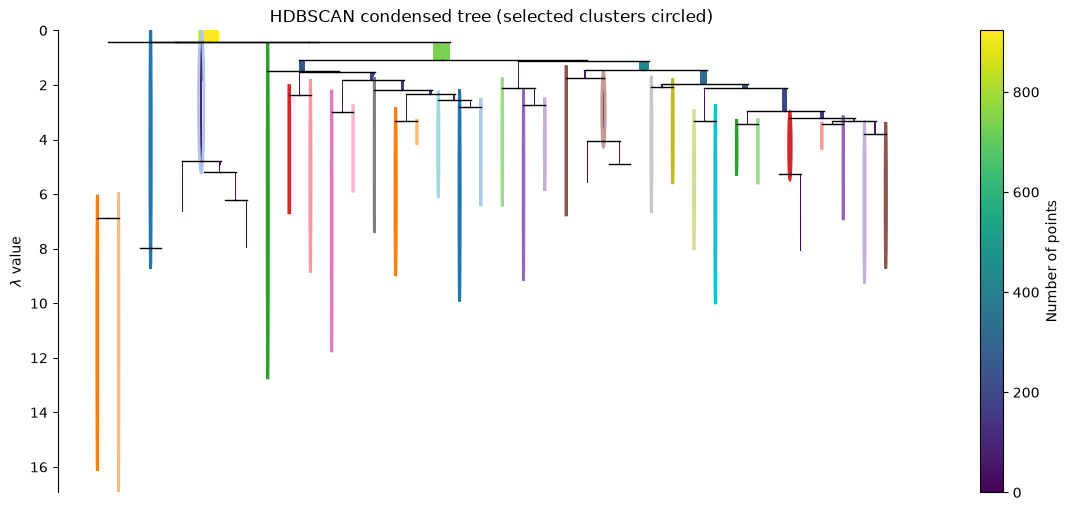

In [7]:
fig, ax = plt.subplots(figsize=(14, 6))
hdb.condensed_tree_.plot(select_clusters=True, selection_palette=sns.color_palette("tab20", 40), axis=ax)
ax.set_title("HDBSCAN condensed tree (selected clusters circled)"); plt.show()

**Membership strength and outlier scores.** Most clustered jobs are firm members; a tail sits on cluster edges.
The highest GLOSH scores point to the most unusual jobs in the data.

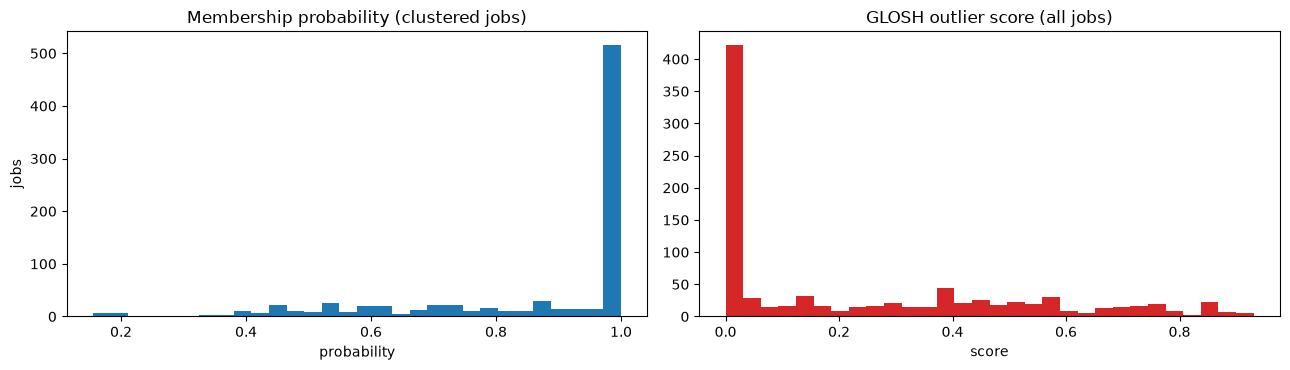

Median membership probability: 1.00


,title,outlier_score,cluster
47,Funeral Home Managers,0.930,-1
66,Coroners,0.930,-1
552,"Morticians, Undertakers, and Funeral Arrangers",0.930,-1
551,Funeral Attendants,0.930,-1
550,Crematory Operators,0.930,-1
549,Embalmers,0.930,-1
850,Dental Laboratory Technicians,0.889,1
381,Oral and Maxillofacial Surgeons,0.889,1
382,Orthodontists,0.889,1
478,Dental Assistants,0.889,1


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].hist(hdb.probabilities_[hdb_labels != -1], bins=30)
ax[0].set(title="Membership probability (clustered jobs)", xlabel="probability", ylabel="jobs")
ax[1].hist(hdb.outlier_scores_, bins=30, color="tab:red")
ax[1].set(title="GLOSH outlier score (all jobs)", xlabel="score")
plt.tight_layout(); plt.show()

outliers = pd.DataFrame({"title": titles, "outlier_score": hdb.outlier_scores_.round(3),
                         "cluster": hdb_labels}).sort_values("outlier_score", ascending=False)
print(f"Median membership probability: {np.median(hdb.probabilities_[hdb_labels != -1]):.2f}")
outliers.head(12)

The top outliers are the six funeral-related jobs (funeral home managers, coroners, embalmers…). They form a tight group of their own, but it's smaller than `min_cluster_size=10`, so HDBSCAN marks them as niche together. Exactly the kind of small, distinctive group the README warns about. In the final bubble hierarchy they end up split by top-level group: embalmers, crematory operators, funeral attendants and morticians sit in Care's *Unique roles* bubble, while funeral home managers land in Connect and coroners in Protect.

## 3. K-Means
Sweep K and use the **elbow (inertia)** and **silhouette** methods to choose it.

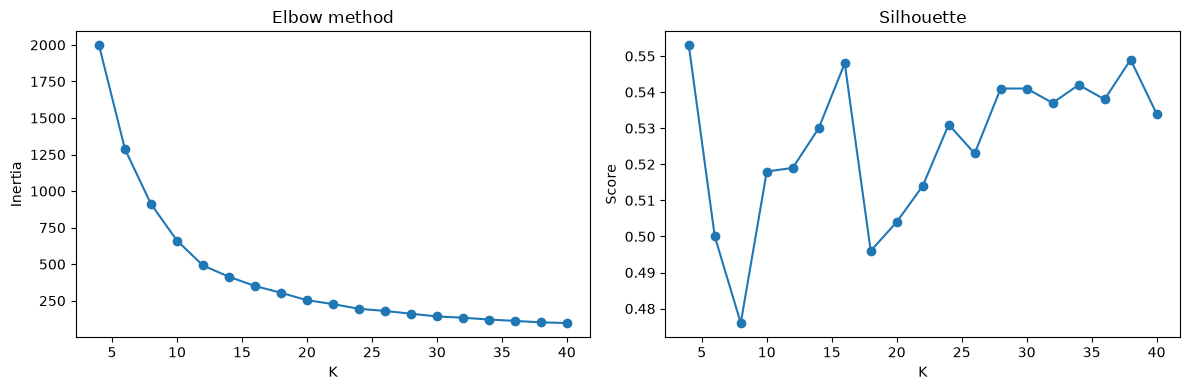

,k,inertia,n_clusters,noise_pct,silhouette,ARI_vs_SOC,ARI_vs_RIASEC
0,4,1998.024658,4,0.0,0.553,0.153,0.291
1,6,1286.533081,6,0.0,0.500,0.249,0.357
2,8,911.616943,8,0.0,0.476,0.308,0.237
3,10,661.532043,10,0.0,0.518,0.316,0.233
4,12,491.314850,12,0.0,0.519,0.345,0.183
5,14,413.975433,14,0.0,0.530,0.359,0.174
6,16,350.868286,16,0.0,0.548,0.378,0.147
7,18,304.436493,18,0.0,0.496,0.381,0.162
8,20,253.725449,20,0.0,0.504,0.382,0.122
9,22,227.371857,22,0.0,0.514,0.378,0.105


In [9]:
km_sweep = sweep_kmeans(X10, ks=range(4, 41, 2), reference=reference)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(km_sweep.k, km_sweep.inertia, "o-"); ax[0].set(title="Elbow method", xlabel="K", ylabel="Inertia")
ax[1].plot(km_sweep.k, km_sweep.silhouette, "o-"); ax[1].set(title="Silhouette", xlabel="K", ylabel="Score")
plt.tight_layout(); plt.show()
km_sweep

**Observations:** silhouette is fairly flat (~0.50–0.54) and the elbow is soft, so there's no single
"correct" K. We pick **K=30** for a fair comparison with HDBSCAN's ~31 clusters, and look at a coarse K=8 later
as a candidate for the top bubble level.

In [10]:
KM_K = 30
km_labels = run_kmeans(X10, KM_K).labels_
score(X10, km_labels, reference)

{'n_clusters': 30,
 'noise_pct': np.float64(0.0),
 'silhouette': 0.541,
 'ARI_vs_SOC': 0.379,
 'ARI_vs_RIASEC': 0.102}

## 4. Side-by-side comparison

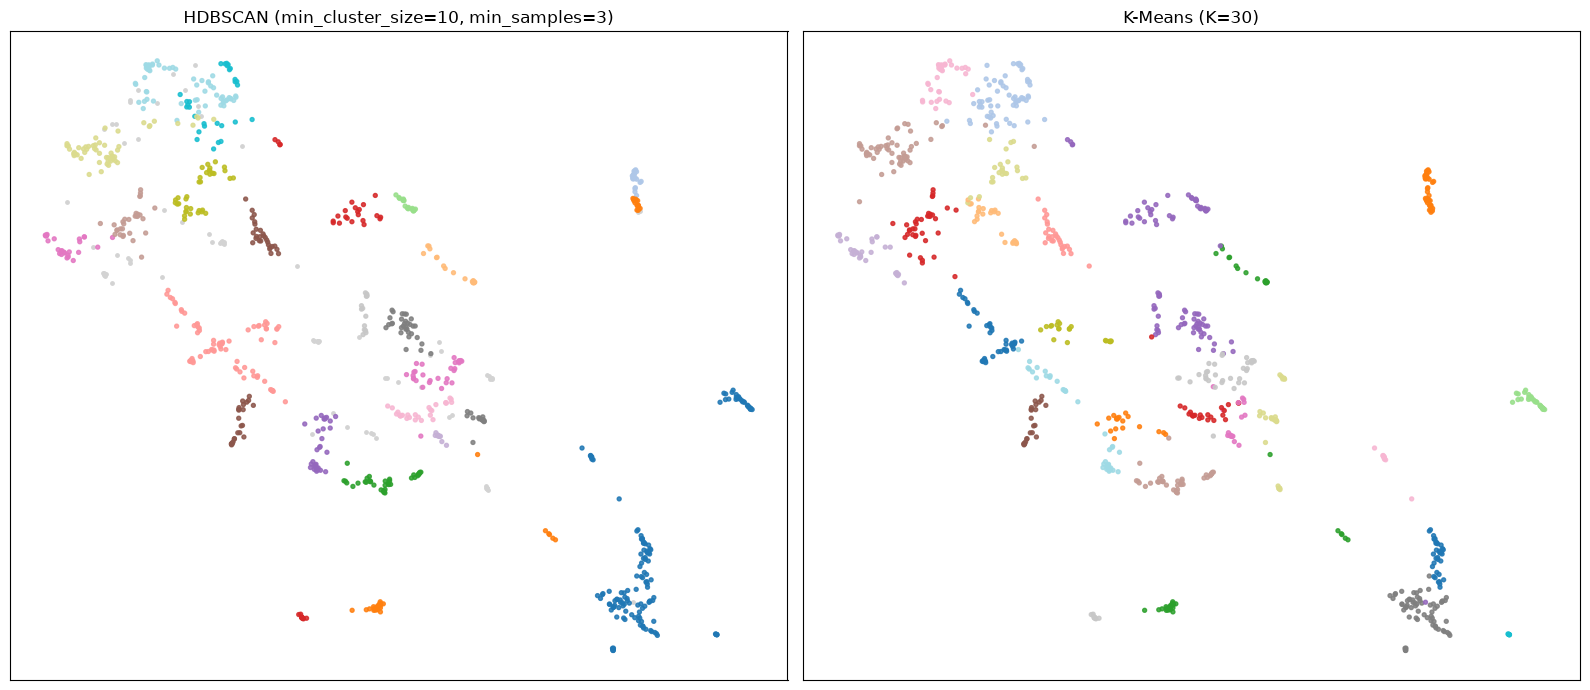

In [11]:
def plot_clusters(ax, labels, title):
    noise = labels == -1
    ax.scatter(X2[noise, 0], X2[noise, 1], s=6, c="lightgrey", label="noise")
    ax.scatter(X2[~noise, 0], X2[~noise, 1], s=8, c=labels[~noise], cmap="tab20", alpha=0.85)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])

fig, ax = plt.subplots(1, 2, figsize=(16, 7))
plot_clusters(ax[0], hdb_labels, f"HDBSCAN (min_cluster_size={HDB_MCS}, min_samples={HDB_MS})")
plot_clusters(ax[1], km_labels, f"K-Means (K={KM_K})")
plt.tight_layout(); plt.show()

In [12]:
from sklearn.metrics import adjusted_rand_score
comparison = pd.DataFrame({
    "HDBSCAN": score(X10, hdb_labels, reference),
    "K-Means": score(X10, km_labels, reference),
}).T
comparison["largest_cluster"] = [np.bincount(hdb_labels[hdb_labels >= 0]).max(), np.bincount(km_labels).max()]
mask = hdb_labels != -1
print(f"Agreement between the two methods (ARI, non-noise jobs): {adjusted_rand_score(hdb_labels[mask], km_labels[mask]):.3f}")
comparison

Agreement between the two methods (ARI, non-noise jobs): 0.707


,n_clusters,noise_pct,silhouette,ARI_vs_SOC,ARI_vs_RIASEC,largest_cluster
HDBSCAN,31.0,8.6,0.604,0.363,0.091,118
K-Means,30.0,0.0,0.541,0.379,0.102,67


## 5. Sanity checks — do similar jobs land together?

In [13]:
checks = ["Registered Nurses", "Software Developers", "Electricians", "Chefs and Head Cooks", "Lawyers", "Elementary School Teachers, Except Special Education"]
rows = []
for t in checks:
    i = titles[titles == t].index[0]
    mates = titles[(hdb_labels == hdb_labels[i]) & (titles != t)].head(4).tolist() if hdb_labels[i] != -1 else ["(noise)"]
    rows.append({"job": t, "HDBSCAN": hdb_labels[i], "K-Means": km_labels[i], "HDBSCAN cluster-mates": "; ".join(mates)})
pd.DataFrame(rows)

,job,HDBSCAN,K-Means,HDBSCAN cluster-mates
0,Registered Nurses,1,21,Clinical Research Coordinators; Fitness and Wellness Coordinators; Health Informatics Specialists; Epidemiologists
1,Software Developers,12,28,Computer and Information Systems Managers; Computer Systems Analysts; Computer and Information Research Scientists; Computer Network Sup...
2,Electricians,26,17,"Insurance Appraisers, Auto Damage; Lighting Technicians; Meter Readers, Utilities; Helpers--Electricians"
3,Chefs and Head Cooks,4,6,Food Service Managers; Dietitians and Nutritionists; Dietetic Technicians; First-Line Supervisors of Food Preparation and Serving Workers
4,Lawyers,6,16,"Judicial Law Clerks; Administrative Law Judges, Adjudicators, and Hearing Officers; Arbitrators, Mediators, and Conciliators; Judges, Ma..."
5,"Elementary School Teachers, Except Special Education",0,8,"Training and Development Managers; Education and Childcare Administrators, Preschool and Daycare; Education Administrators, Kindergarten..."


### Jobs HDBSCAN treats as noise (niche / hard to place)

In [14]:
titles[hdb_labels == -1].sample(15, random_state=1).tolist()

['Model Makers, Metal and Plastic',
 'Title Examiners, Abstractors, and Searchers',
 'Gambling Dealers',
 'Captains, Mates, and Pilots of Water Vessels',
 'Log Graders and Scalers',
 'Solar Energy Installation Managers',
 'Solar Photovoltaic Installers',
 'Aviation Inspectors',
 'Solar Sales Representatives and Assessors',
 'Transportation Inspectors',
 'Crematory Operators',
 'Electrical and Electronic Equipment Assemblers',
 'Morticians, Undertakers, and Funeral Arrangers',
 'Real Estate Brokers',
 'Camera and Photographic Equipment Repairers']

### What's in each HDBSCAN cluster

In [15]:
cluster_summary(hdb_labels, titles, n_examples=4)

,size,examples
cluster,,
-1,79,Chief Executives; Legislators; Fundraising Managers; Gambling Managers
0,30,"Training and Development Managers; Education and Childcare Administrators, Preschool and Daycare; Education Administrators, Kindergarten..."
1,118,Clinical Research Coordinators; Fitness and Wellness Coordinators; Health Informatics Specialists; Epidemiologists
2,21,"Education Administrators, Postsecondary; Astronomers; Computer Science Teachers, Postsecondary; Mathematical Science Teachers, Postsecon..."
3,16,"Business Teachers, Postsecondary; Architecture Teachers, Postsecondary; Area, Ethnic, and Cultural Studies Teachers, Postsecondary; Econ..."
4,28,Food Service Managers; Dietitians and Nutritionists; Dietetic Technicians; Chefs and Head Cooks
5,18,Document Management Specialists; Anthropologists and Archeologists; Historians; Archivists
6,10,"Lawyers; Judicial Law Clerks; Administrative Law Judges, Adjudicators, and Hearing Officers; Arbitrators, Mediators, and Conciliators"
7,27,Security Managers; Loss Prevention Managers; Government Property Inspectors and Investigators; Business Continuity Planners


## 6. Findings

| | HDBSCAN | K-Means |
|---|---|---|
| Clusters | found automatically (~31) | must choose K |
| Noise / outliers | flags ~9% as niche | forces every job into a cluster |
| Silhouette (non-noise) | higher (~0.60) | lower (~0.54) |
| Cluster sizes | uneven, follows the data (largest = 118, all of healthcare) | more even (largest = 67) |
| Agreement with each other | ARI ≈ 0.71 on non-noise jobs | |

- **UMAP is what makes HDBSCAN work:** on raw or PCA vectors HDBSCAN calls 38–66% of jobs noise; after UMAP ~9% (section 1b).
- Both methods agree on obvious groups (legal, culinary, IT, construction trades, postsecondary teachers).
- **Managers cluster with each other** rather than with their field (e.g. many "… Managers" share planning/budget
  language). Worth handling in the hierarchy step so "Nursing" includes nurse managers.
- Agreement with SOC job families is moderate (ARI ~0.35–0.4): the text clusters capture *what people do*,
  which partly cuts across the official taxonomy. Agreement with RIASEC is low at this granularity, as expected (only 6 interest types).

**Recommendation:** use HDBSCAN for the detailed (level 2) bubbles, with noise jobs assigned to their nearest cluster
for display (`hdbscan.approximate_predict` / soft clustering) but flagged as "niche".

In [16]:
out = pd.DataFrame({"code": codes, "title": titles, "hdbscan": hdb_labels, "kmeans": km_labels,
                    "umap_x": X2[:, 0], "umap_y": X2[:, 1]})
out.to_csv(PROCESSED / "text_clusters.csv", index=False)
out.head()

,code,title,hdbscan,kmeans,umap_x,umap_y
0,11-1011.00,Chief Executives,-1,18,4.639502,6.652008
1,11-1011.03,Chief Sustainability Officers,11,0,1.519981,7.350053
2,11-1021.00,General and Operations Managers,22,12,4.409559,7.249920
3,11-1031.00,Legislators,-1,22,4.275961,6.729809
4,11-2011.00,Advertising and Promotions Managers,22,12,4.583533,7.442673
